## 1 读取与检查数据

旅客单位为入境人次；博彩收入单位为百万澳门元，采用 games of fortune 的 gross revenue，不混用所有博彩活动总额。

In [1]:
# CISC7204 Assignment 02 Pair 01
# Simple monthly extension of the Assignment 01 recovery comparison.
# Run this notebook from the proposal folder. Requires pandas and matplotlib.
# Sources, definitions and rounding checks: see the source record at the end of this notebook.

import pandas as pd
import matplotlib.pyplot as plt

# 1 Read the two official monthly datasets.
visitors = pd.read_csv('data/visitor_monthly.csv')
gaming = pd.read_csv('data/gaming_monthly.csv')
monthly = pd.merge(visitors, gaming, on=['Year', 'Month'])
print('Monthly rows:', len(monthly))
print('Missing values:')
print(monthly.isna().sum())
print('Duplicate months:', monthly.duplicated(['Year', 'Month']).sum())



Monthly rows: 48
Missing values:
Year              0
Month             0
Visitors          0
Gaming_Revenue    0
dtype: int64
Duplicate months: 0


## 2 计算同月复苏指数

按 Month 与 2019 年匹配。指数 = 本月值 / 2019 年同月值 × 100；差距 = 旅客指数 − 博彩指数，单位为百分点。总计 36 个分析月份。

In [2]:
# 2 Match each month to the same month of 2019.
baseline = monthly[monthly['Year'] == 2019][['Month', 'Visitors', 'Gaming_Revenue']]
baseline = baseline.rename(columns={'Visitors': 'Visitors_2019',
                                    'Gaming_Revenue': 'Gaming_2019'})
df = monthly[monthly['Year'] >= 2023].copy()
df = pd.merge(df, baseline, on='Month')
df = df.sort_values(['Year', 'Month']).reset_index(drop=True)
df['Visitor_Index'] = df['Visitors'] / df['Visitors_2019'] * 100
df['Gaming_Index'] = df['Gaming_Revenue'] / df['Gaming_2019'] * 100
df['Gap'] = df['Visitor_Index'] - df['Gaming_Index']
df['Period'] = df['Year'].astype(str) + '-' + df['Month'].astype(str).str.zfill(2)
print(df[['Period', 'Visitor_Index', 'Gaming_Index', 'Gap']].round(1))



     Period  Visitor_Index  Gaming_Index   Gap
0   2023-01           40.8          46.4  -5.6
1   2023-02           44.9          40.7   4.3
2   2023-03           57.7          49.3   8.4
3   2023-04           66.3          62.4   3.8
4   2023-05           65.2          60.0   5.2
5   2023-06           71.4          63.9   7.5
6   2023-07           78.2          68.1  10.0
7   2023-08           88.9          70.9  18.0
8   2023-09           83.2          67.7  15.6
9   2023-10           85.9          73.7  12.2
10  2023-11           88.8          70.1  18.7
11  2023-12           95.5          81.3  14.2
12  2024-01           83.5          77.5   6.0
13  2024-02           92.9          72.9  20.0
14  2024-03           80.3          75.5   4.8
15  2024-04           75.8          78.6  -2.8
16  2024-05           79.3          77.8   1.5
17  2024-06           82.4          74.3   8.1
18  2024-07           85.6          76.0   9.5
19  2024-08          100.8          81.4  19.4
20  2024-09  

## 3 汇总与年度核对

用 groupby 统计每年 12 个月的差距，并核对逐月总和。2019 年公布月值之和比公布年值多 1 百万澳门元；保留原始值，月度图用月值，年度图用公布年值。

In [3]:
# 3 Summarize the monthly gaps and compare sums with published annual totals.
summary = df.groupby('Year')['Gap'].agg(['mean', 'median', 'min', 'max'])
print('\nMonthly gap summary (percentage points):')
print(summary.round(1))
print('\nLargest monthly gap:')
print(df.loc[df['Gap'].idxmax(), ['Period', 'Visitor_Index', 'Gaming_Index', 'Gap']])
print('\nSmallest monthly gap:')
print(df.loc[df['Gap'].idxmin(), ['Period', 'Visitor_Index', 'Gaming_Index', 'Gap']])
print('\nMonths at or above the 2019 monthly level:')
print(df[df['Visitor_Index'] >= 100].groupby('Year').size().reindex([2023, 2024, 2025], fill_value=0))
print('Gaming months at or above 100:', (df['Gaming_Index'] >= 100).sum())
annual = pd.read_csv('data/annual_2019_2025.csv').set_index('Year')
sums = monthly.groupby('Year')[['Visitors', 'Gaming_Revenue']].sum()
check = sums - annual.loc[sums.index, ['Visitors', 'Gaming_Revenue']]
print('\nMonthly sums minus official annual totals:')
print(check)
# DICJ reports monthly values in whole MOP million. For 2019 their sum is
# 292456, versus the official annual 292455. Keep both published measures.




Monthly gap summary (percentage points):
      mean  median  min   max
Year                         
2023   9.3     9.2 -5.6  18.7
2024  11.2    11.4 -2.8  20.0
2025  17.2    17.3  4.9  33.3

Largest monthly gap:
Period              2025-01
Visitor_Index    106.465018
Gaming_Index      73.185791
Gap               33.279227
Name: 24, dtype: object

Smallest monthly gap:
Period             2023-01
Visitor_Index    40.808659
Gaming_Index     46.427712
Gap              -5.619053
Name: 0, dtype: object

Months at or above the 2019 monthly level:
Year
2023    0
2024    1
2025    6
dtype: int64
Gaming months at or above 100: 0

Monthly sums minus official annual totals:
      Visitors  Gaming_Revenue
Year                          
2019         0               1
2023         0               0
2024         0               0
2025         0               0


**数据核对：**两份月度输入均有 48 行，没有缺失或重复的年份月份键。旅客逐月总数与四个年度值全部一致。博彩收入的 2023–2025 年逐月总数与年值一致；2019 年相差 1 百万澳门元，约为该年总额的 0.00034%。

## 4 年度折线图

保留第一次 proposal 的年度比较，提供 2019–2025 年的整体背景。

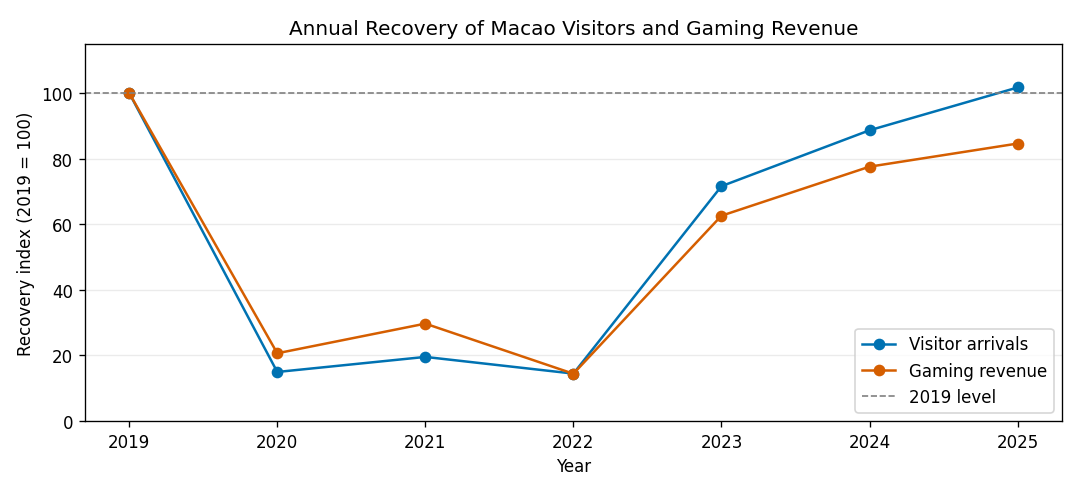

In [4]:
# 4 Annual line chart: extend the original Assignment 01 chart.
annual['Visitor_Index'] = annual['Visitors'] / annual.loc[2019, 'Visitors'] * 100
annual['Gaming_Index'] = annual['Gaming_Revenue'] / annual.loc[2019, 'Gaming_Revenue'] * 100
annual[['Visitor_Index', 'Gaming_Index']].plot(
    kind='line', figsize=(9, 4.1), marker='o', color=['#0072B2', '#D55E00'])
plt.axhline(100, color='gray', linestyle='--', linewidth=1)
plt.title('Annual Recovery of Macao Visitors and Gaming Revenue')
plt.xlabel('Year')
plt.ylabel('Recovery index (2019 = 100)')
plt.xticks(annual.index)
plt.ylim(0, 115)
plt.legend(['Visitor arrivals', 'Gaming revenue', '2019 level'])
plt.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.savefig('figures/01_annual_recovery.png', dpi=180)
plt.show()
plt.close()



**年度结果：**2025 年旅客复苏指数为 101.7，博彩收入为 84.6，相差约 17.1 个百分点。这保留并核实了第一次 proposal 的主要观察。

## 5 月度折线图

深化后的核心图表。每个月对比 2019 年同月，避免直接把淡旺季月份当作相同基准。该做法不是完整的季节调整。

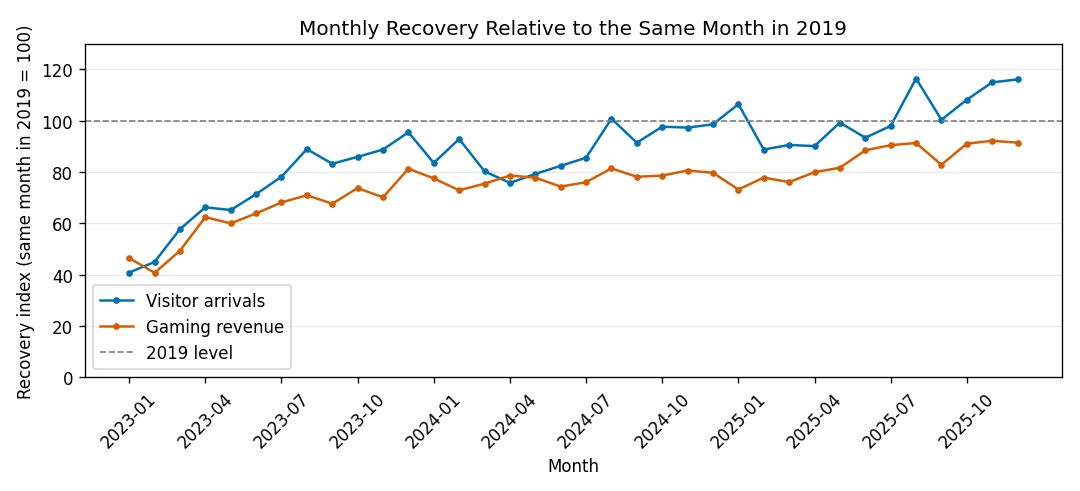

In [5]:
# 5 Monthly line chart: same plotting method as Module 01 Lab 02.
df.set_index('Period')[['Visitor_Index', 'Gaming_Index']].plot(
    kind='line', figsize=(9, 4.1), marker='o', markersize=3,
    color=['#0072B2', '#D55E00'])
plt.axhline(100, color='gray', linestyle='--', linewidth=1)
plt.title('Monthly Recovery Relative to the Same Month in 2019')
plt.xlabel('Month')
plt.ylabel('Recovery index (same month in 2019 = 100)')
plt.xticks(range(0, 36, 3), df['Period'].iloc[::3], rotation=45)
plt.ylim(0, 130)
plt.legend(['Visitor arrivals', 'Gaming revenue', '2019 level'])
plt.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.savefig('figures/02_monthly_recovery.png', dpi=180)
plt.show()
plt.close()



**月度结果：**2023、2024、2025 年分别有 0、1、6 个月的旅客人次达到或超过 2019 年同月；36 个月中博彩收入都没有达到基准。2025 年并不是每个月的旅客人次都超过 2019 年。

## 6 月度差距柱状图

正值表示旅客人次的复苏指数较高；负值表示博彩收入复苏指数较高。所有柱子共用零基线。

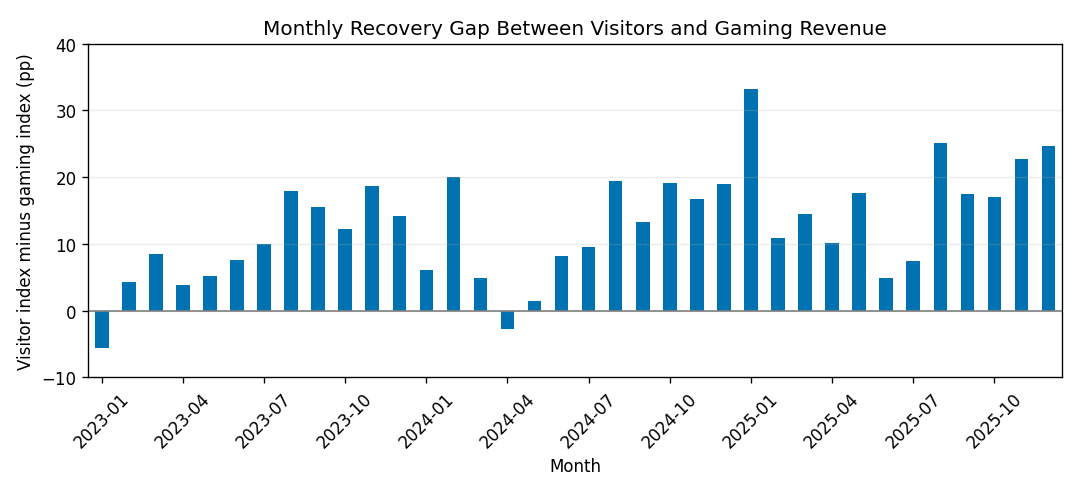

In [6]:
# 6 Monthly bar chart: same method as Module 02 Lab 01.
df.set_index('Period')['Gap'].plot(kind='bar', figsize=(9, 4.1), color='#0072B2')
plt.axhline(0, color='gray', linewidth=1)
plt.title('Monthly Recovery Gap Between Visitors and Gaming Revenue')
plt.xlabel('Month')
plt.ylabel('Visitor index minus gaming index (pp)')
plt.xticks(range(0, 36, 3), df['Period'].iloc[::3], rotation=45)
plt.ylim(-10, 40)
plt.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.savefig('figures/03_monthly_gap.png', dpi=180)
plt.show()
plt.close()



**差距结果：**最大差距出现在 2025 年 1 月，为 33.3 个百分点（旅客指数 106.5，博彩指数 73.2）；最小差距出现在 2023 年 1 月，为 -5.6 个百分点。36 个月中 34 个月差距为正。农历新年等节假日在不同年份落入不同月份，因此不能把某月差距直接归因为某种政策或消费行为。

## 7 按年比较月度差距的箱线图

每组有 12 个月。箱体表示中间 50% 的月份，中线是中位数，须线与孤立点按 Matplotlib 默认的 1.5 IQR 规则绘制。箱线图的点不是无效数据，不应直接删除。

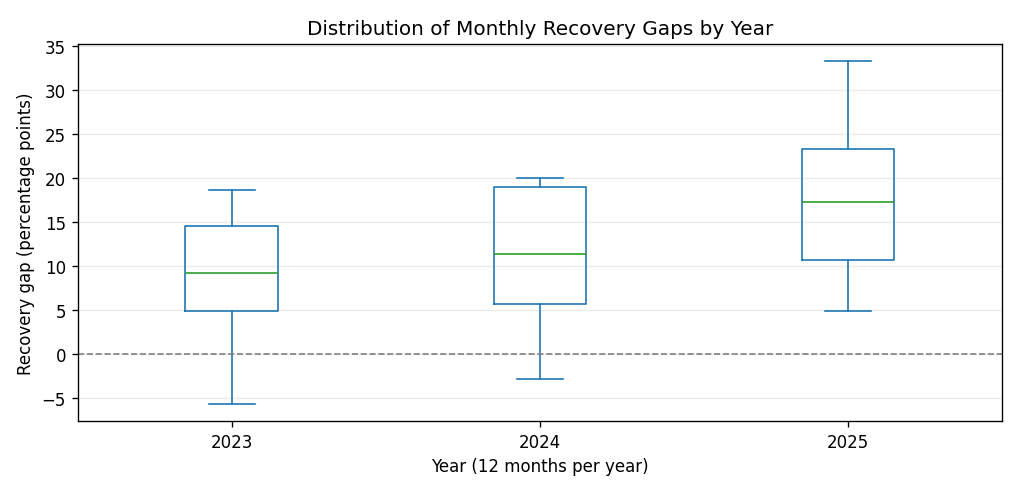

In [7]:
# 7 Box plot: compare the 12 monthly gaps in each year (Module 02 Lab 02).
gaps_by_year = df.pivot(index='Month', columns='Year', values='Gap')
gaps_by_year.plot(kind='box', figsize=(8.5, 4.1))
plt.axhline(0, color='gray', linestyle='--', linewidth=1)
plt.title('Distribution of Monthly Recovery Gaps by Year')
plt.xlabel('Year (12 months per year)')
plt.ylabel('Recovery gap (percentage points)')
plt.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.savefig('figures/04_gap_boxplot.png', dpi=180)
plt.show()
plt.close()



**年度分布结果：**平均月度差距从 2023 年的 9.3 扩大到 2024 年的 11.2 和 2025 年的 17.2 个百分点；中位数依次为 9.2、11.4、17.3。两种汇总都支持差距扩大，但不表示差距逐月单调上升，也不表示所有月份旅客都恢复得更快。

## 8 导出计算表

CSV 保留完整计算精度。

In [8]:
# 8 Save calculated values without rounding the underlying data.
monthly.to_csv('data/monthly_merged.csv', index=False)
df.to_csv('data/monthly_recovery_results.csv', index=False)
summary.to_csv('data/monthly_gap_summary.csv')
check.to_csv('data/annual_total_check.csv')
annual.to_csv('data/annual_recovery_results.csv')
print('\nSaved four figures and the calculated tables.')



Saved four figures and the calculated tables.


## 解释的边界

这是总量描述性分析，收入没有通胀调整，旅客也不等于博彩参与者。博彩收入可能包含居民支出，不能把两个序列相除后称为每位旅客的实际博彩消费。2019 年同月基准只能减少通常的淡旺季差异，不能消除节假日错位、游客构成变化等因素。没有因果推断或预测。

## 官方数据来源与核对记录

# Source record and data checks

Retrieved and checked on 20 October 2026. This folder contains the completed monthly analysis for Assignment 02 Pair 01, extending the Assignment 01 topic.

## Monthly visitor arrivals

Macao Government Tourism Office (MGTO), Total Visitor Arrivals, showing **Source: DSEC**. Filter: monthly, January 2019 to December 2025.

https://dataplus.macaotourism.gov.mo/Indicator/VisitorsSummary/SummaryBar?lang=E&periodtype=M&start=241&end=324

The official page contains the month categories and the Total_Value data series. The archived page is `data/source_files/visitors_mgto_2019_2025.html`. The source page covers all 84 months in 2019–2025; the project selects only 2019 and 2023–2025, producing 48 rows in `visitor_monthly.csv`. Units: arrival counts, not unique individuals. All four yearly sums equal the official annual totals.

## Monthly gaming revenue

Gaming Inspection and Coordination Bureau (DICJ), Monthly Gross Revenue from Games of Fortune. The official HTML pages link to the following data files:

- 2019: https://www.dicj.gov.mo/web/en/information/DadosEstat_mensal/2019/report_en.xml
- 2023: https://www.dicj.gov.mo/web/en/information/DadosEstat_mensal/2023/report_en.xml
- 2024: https://www.dicj.gov.mo/web/en/information/DadosEstat_mensal/2024/report_en.xml
- 2025: https://www.dicj.gov.mo/web/en/information/DadosEstat_mensal/2025/report_en.xml

The source pages are the same addresses with `index.html` in place of `report_en.xml`. Original XML files are archived in `data/source_files`. Use the current year's **Monthly Gross Revenue** column, not the preceding-year comparison or the accumulated column. Units: MOP million; nominal gross revenue from games of fortune. The data do not represent the total of every gaming activity. The extracted values are in `gaming_monthly.csv`.

## Annual background data

The seven annual rows continue the Assignment 01 dataset, checked against:

- Visitor totals 2019–2023: Macao Yearbook 2024, Appendix 19, Tourism. https://yearbook.gcs.gov.mo/uploads/yearbook_pdf/2024/myb2024eAP19.pdf
- DSEC 2024 visitor release: https://www.gcs.gov.mo/news/detail/en/N25AUB2Zwi
- DSEC 2025 visitor release: https://www.gcs.gov.mo/news/detail/en/N26AWC98hd
- DICJ 2021 statistics, games of fortune row, for 2019: https://www.dicj.gov.mo/web/cn/information/DadosEstat/2021/content.html
- DICJ 2025 statistics, games of fortune row, for 2020–2025: https://www.dicj.gov.mo/web/pt/information/DadosEstat/2025/content.html

The 2025 gaming annual value is 247404 MOP million, replacing the rounded 247400 in the Assignment 01 code.

## Reconciliation and calculation rules

- Each input CSV contains 48 unique Year–Month keys with no missing values. The merge has 48 rows; the 2019 baseline has 12 rows; the study has 36 months in 2023–2025.
- Visitor monthly sums agree exactly with the annual values for 2019, 2023, 2024, and 2025.
- Gaming monthly sums agree with the annual values in 2023–2025.
- The published 2019 monthly gaming values sum to **292456** MOP million, while the published annual total is **292455**. Both are retained. The difference of 1 MOP million is about 0.00034% of the annual value. Monthly values are published in whole MOP million; the monthly and cumulative columns can therefore differ slightly when summed. Do not silently adjust a month to force agreement.
- Monthly indices use the corresponding published 2019 monthly value. The annual chart uses the published annual totals, including 292455 for 2019. Annual indices are not averages of monthly indices.
- Gap = visitor recovery index minus gaming recovery index, measured in percentage points. Summary means and medians each use the 12 monthly gaps in the given year.
- Underlying calculations are not rounded. Text reports one decimal place. Tables and CSVs retain more precision.

The raw values and all outputs are local; rerunning the analysis does not require internet access.

## Exercise references

Module 01 Lab 02: `DataFrame.plot(kind='line')`.
Module 02 Lab 01: `Series.plot(kind='bar')`.
Module 02 Lab 02: `DataFrame.plot(kind='box')`.

The script uses only pandas and Matplotlib, with basic merging, filtering, groupby, pivot, labels and reference lines. Data retrieval is kept outside the student-facing analysis script.
